# Phase 2: Segmentation and Features
This notebook implements Phase 2 for the Da Nang Sentinel-2 assignment.

Manual requirements covered here:
1. Detect edges/features in the scene using Canny and ORB.
2. Segment the scene into land-cover regions using OpenCV mean-shift filtering plus spectral-index interpretation.
3. Validate 5 selected regions against a basemap-style reference and report where the segmentation matches or is limited.

The AOI was exported as two overlapping pieces (`above` and `below`). Phase 2 processes both pieces independently on the 2024 reference date; stitching/alignment is reserved for Phase 3.


In [1]:
import csv
import math
import urllib.request
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
from matplotlib.patches import Patch, Rectangle

# Paths are relative to this notebook when run from the works directory.
dataset_dir = Path("../dataset")
output_dir = Path("../output")
output_dir.mkdir(parents=True, exist_ok=True)

reference_year = "2024"
reference_date_label = "April 11, 2024"
reference_dir = dataset_dir / "2024_04_11"

crops = {
    "above": "Upper AOI crop",
    "below": "Lower AOI crop",
}

print(f"Dataset directory: {dataset_dir.resolve()}")
print(f"Output directory: {output_dir.resolve()}")


Dataset directory: /home/dacekey/CPV301_SUM26/main/L27_Assignment_*/dataset
Output directory: /home/dacekey/CPV301_SUM26/main/L27_Assignment_*/output


In [2]:
def find_one(folder, pattern):
    matches = sorted(folder.glob(pattern))
    if not matches:
        raise FileNotFoundError(f"No file matching {pattern!r} in {folder}")
    if len(matches) > 1:
        print(f"Warning: multiple matches for {pattern!r} in {folder}; using {matches[0].name}")
    return matches[0]


def crop_folder(crop_key):
    return reference_dir / f"{crop_key}_{reference_year}"


def normalize_to_uint8(image):
    return cv2.normalize(image, None, 0, 255, cv2.NORM_MINMAX, dtype=cv2.CV_8U)


def load_true_color(path):
    image = cv2.imread(str(path), cv2.IMREAD_UNCHANGED)
    if image is None:
        raise FileNotFoundError(f"Cannot load image: {path}")
    if image.ndim != 3 or image.shape[2] < 3:
        raise ValueError(f"Expected a 3-channel true-color image for {path}, got shape {image.shape}")
    rgb = cv2.cvtColor(image[:, :, :3], cv2.COLOR_BGR2RGB)
    return normalize_to_uint8(rgb)


def load_band(path):
    band = cv2.imread(str(path), cv2.IMREAD_UNCHANGED)
    if band is None:
        raise FileNotFoundError(f"Cannot load image: {path}")
    if band.ndim != 2:
        raise ValueError(f"Expected single-band TIFF for {path}, got shape {band.shape}")
    return band.astype(np.float32)


def safe_index(numerator, denominator):
    return np.divide(
        numerator,
        denominator,
        out=np.zeros_like(numerator, dtype=np.float32),
        where=denominator != 0,
    )


def calculate_ndvi(red, nir):
    if red.shape != nir.shape:
        raise ValueError(f"Band shape mismatch: Red {red.shape}, NIR {nir.shape}")
    return safe_index(nir - red, nir + red)


def calculate_ndwi(green, nir):
    if green.shape != nir.shape:
        raise ValueError(f"Band shape mismatch: Green {green.shape}, NIR {nir.shape}")
    return safe_index(green - nir, green + nir)


def auto_canny(gray, sigma=0.33):
    blurred = cv2.GaussianBlur(gray, (5, 5), 0)
    median = float(np.median(blurred))
    lower = int(max(0, (1.0 - sigma) * median))
    upper = int(min(255, (1.0 + sigma) * median))
    edges = cv2.Canny(blurred, lower, upper)
    return edges, lower, upper


def save_figure(fig, filename):
    path = output_dir / filename
    fig.savefig(path, dpi=200, bbox_inches="tight")
    print(f"Saved: {path}")
    return path


def read_georef(path):
    # Sentinel Hub GeoTIFF exports store WGS84 tiepoint and pixel scale tags.
    image = Image.open(path)
    tags = image.tag_v2
    tiepoint = tags.get(33922)
    scale = tags.get(33550)
    if tiepoint is None or scale is None:
        raise ValueError(f"Missing GeoTIFF tiepoint/pixel-scale tags in {path}")
    lon0 = float(tiepoint[3])
    lat0 = float(tiepoint[4])
    scale_x = float(scale[0])
    scale_y = float(scale[1])
    width, height = image.size
    return {
        "lon0": lon0,
        "lat0": lat0,
        "scale_x": scale_x,
        "scale_y": scale_y,
        "width": width,
        "height": height,
        "lon_min": lon0,
        "lon_max": lon0 + width * scale_x,
        "lat_max": lat0,
        "lat_min": lat0 - height * scale_y,
    }


def pixel_to_lonlat(georef, x, y):
    lon = georef["lon0"] + x * georef["scale_x"]
    lat = georef["lat0"] - y * georef["scale_y"]
    return lon, lat


In [3]:
scene_data = {}

for crop_key, crop_label in crops.items():
    folder = crop_folder(crop_key)
    true_color_path = find_one(folder, "*True_color*.tiff")
    red_path = find_one(folder, "*B04*.tiff")
    green_path = find_one(folder, "*B03*.tiff")
    nir_path = find_one(folder, "*B08*.tiff")

    rgb = load_true_color(true_color_path)
    red = load_band(red_path)
    green = load_band(green_path)
    nir = load_band(nir_path)

    if rgb.shape[:2] != red.shape:
        raise ValueError(f"True-color and band shape mismatch for {crop_key}: {rgb.shape[:2]} vs {red.shape}")

    ndvi = calculate_ndvi(red, nir)
    ndwi = calculate_ndwi(green, nir)
    gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
    georef = read_georef(red_path)

    scene_data[crop_key] = {
        "label": crop_label,
        "rgb": rgb,
        "gray": gray,
        "red": red,
        "green": green,
        "nir": nir,
        "ndvi": ndvi,
        "ndwi": ndwi,
        "georef": georef,
    }

    print(
        f"{crop_label}: rgb={rgb.shape}, bands={red.shape}, "
        f"lon=({georef['lon_min']:.6f}, {georef['lon_max']:.6f}), "
        f"lat=({georef['lat_min']:.6f}, {georef['lat_max']:.6f})"
    )


Upper AOI crop: rgb=(252, 774, 3), bands=(252, 774), lon=(108.205719, 108.344765), lat=(16.119543, 16.163075)
Lower AOI crop: rgb=(313, 743, 3), bands=(313, 743), lon=(108.205719, 108.339272), lat=(16.073692, 16.127788)


Saved: ../output/phase2_feature_summary.csv

Feature detection summary
- above: Canny 45/90, edge density=0.0241, ORB keypoints=250
- below: Canny 41/82, edge density=0.0700, ORB keypoints=250
Saved: ../output/phase2_canny_edges_2024.png
Saved: ../output/phase2_orb_keypoints_2024.png


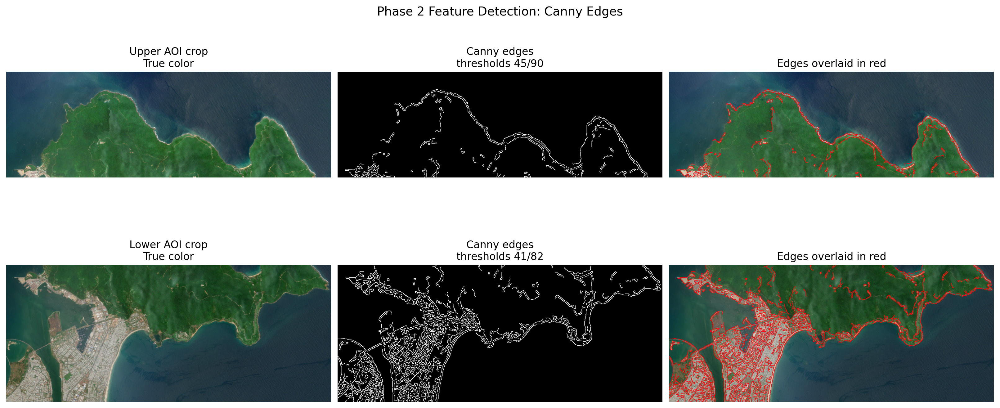

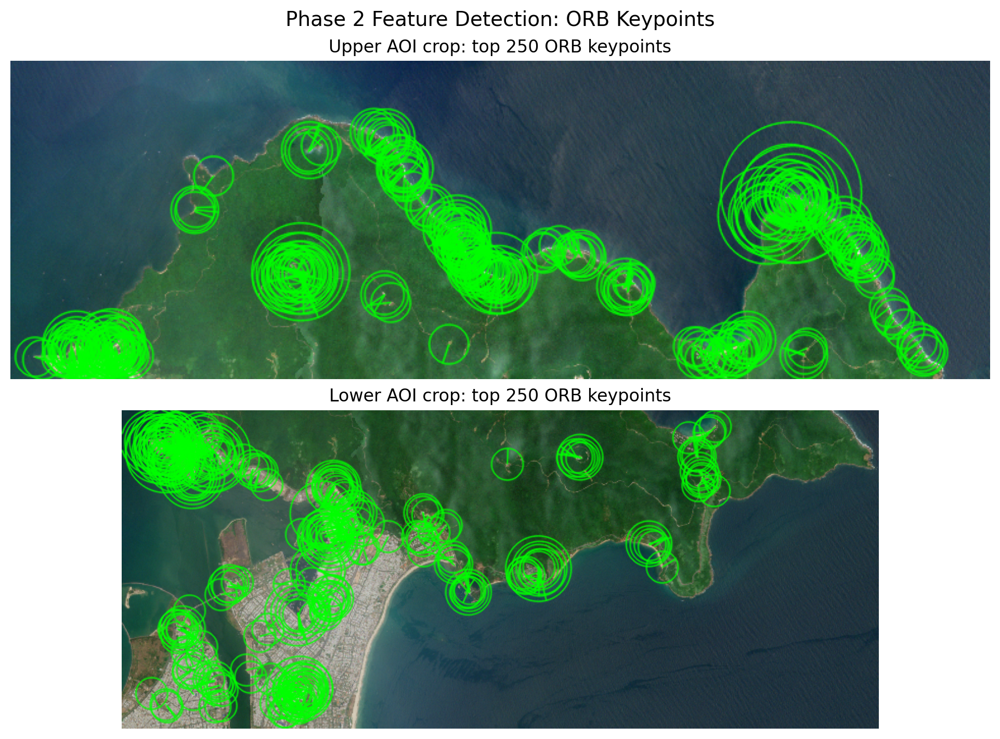

In [4]:
feature_rows = []
edge_results = {}
orb_results = {}

orb = cv2.ORB_create(nfeatures=800, scaleFactor=1.2, nlevels=8, edgeThreshold=15)

fig_edges, axes_edges = plt.subplots(len(crops), 3, figsize=(16, 7), constrained_layout=True)
fig_orb, axes_orb = plt.subplots(len(crops), 1, figsize=(14, 7), constrained_layout=True)

for row_idx, (crop_key, crop_label) in enumerate(crops.items()):
    rgb = scene_data[crop_key]["rgb"]
    gray = scene_data[crop_key]["gray"]

    edges, lower, upper = auto_canny(gray)
    edge_overlay = rgb.copy()
    edge_overlay[edges > 0] = [255, 0, 0]

    keypoints = orb.detect(gray, None)
    keypoints = sorted(keypoints, key=lambda kp: kp.response, reverse=True)[:250]
    keypoint_image = cv2.drawKeypoints(
        rgb,
        keypoints,
        None,
        color=(0, 255, 0),
        flags=cv2.DrawMatchesFlags_DRAW_RICH_KEYPOINTS,
    )

    edge_results[crop_key] = edges
    orb_results[crop_key] = keypoints

    edge_count = int(np.count_nonzero(edges))
    edge_density = edge_count / edges.size
    feature_rows.append({
        "crop": crop_key,
        "canny_low": lower,
        "canny_high": upper,
        "edge_pixels": edge_count,
        "edge_density": edge_density,
        "orb_keypoints": len(keypoints),
    })

    axes_edges[row_idx, 0].imshow(rgb)
    axes_edges[row_idx, 0].set_title(f"{crop_label}\nTrue color")
    axes_edges[row_idx, 1].imshow(edges, cmap="gray")
    axes_edges[row_idx, 1].set_title(f"Canny edges\nthresholds {lower}/{upper}")
    axes_edges[row_idx, 2].imshow(edge_overlay)
    axes_edges[row_idx, 2].set_title("Edges overlaid in red")
    for col_idx in range(3):
        axes_edges[row_idx, col_idx].axis("off")

    axes_orb[row_idx].imshow(keypoint_image)
    axes_orb[row_idx].set_title(f"{crop_label}: top {len(keypoints)} ORB keypoints")
    axes_orb[row_idx].axis("off")

feature_summary_path = output_dir / "phase2_feature_summary.csv"
with feature_summary_path.open("w", newline="") as f:
    writer = csv.DictWriter(
        f,
        fieldnames=["crop", "canny_low", "canny_high", "edge_pixels", "edge_density", "orb_keypoints"],
    )
    writer.writeheader()
    writer.writerows(feature_rows)

print(f"Saved: {feature_summary_path}")
print("\nFeature detection summary")
for row in feature_rows:
    print(
        f"- {row['crop']}: Canny {row['canny_low']}/{row['canny_high']}, "
        f"edge density={row['edge_density']:.4f}, ORB keypoints={row['orb_keypoints']}"
    )

fig_edges.suptitle("Phase 2 Feature Detection: Canny Edges", fontsize=14)
save_figure(fig_edges, "phase2_canny_edges_2024.png")
plt.show()

fig_orb.suptitle("Phase 2 Feature Detection: ORB Keypoints", fontsize=14)
save_figure(fig_orb, "phase2_orb_keypoints_2024.png")
plt.show()


Saved: ../output/phase2_mean_shift_landcover_segmentation_2024.png
Saved: ../output/phase2_landcover_area_summary.csv

Land-cover area summary
- above / Water: 61.96%
- above / Dense vegetation: 36.72%
- above / Built-up/bare: 0.87%
- above / Sand/exposed soil: 0.14%
- above / Mixed/shadow: 0.30%
- below / Water: 52.50%
- below / Dense vegetation: 32.81%
- below / Built-up/bare: 11.29%
- below / Sand/exposed soil: 0.69%
- below / Mixed/shadow: 2.70%


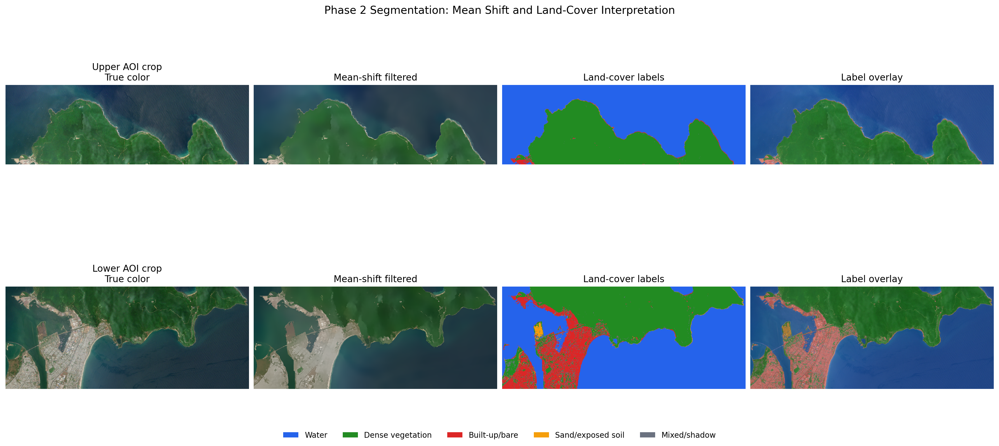

In [5]:
label_names = {
    0: "Water",
    1: "Dense vegetation",
    2: "Built-up/bare",
    3: "Sand/exposed soil",
    4: "Mixed/shadow",
}

label_colors = np.array([
    [37, 99, 235],     # water: blue
    [34, 139, 34],     # vegetation: green
    [220, 38, 38],     # built-up/bare: red
    [245, 158, 11],    # sand/exposed soil: orange
    [107, 114, 128],   # mixed/shadow: gray
], dtype=np.uint8)

segmentation_results = {}
area_rows = []

fig, axes = plt.subplots(len(crops), 4, figsize=(18, 8), constrained_layout=True)

for row_idx, (crop_key, crop_label) in enumerate(crops.items()):
    rgb = scene_data[crop_key]["rgb"]
    ndvi = scene_data[crop_key]["ndvi"]
    ndwi = scene_data[crop_key]["ndwi"]

    # Mean shift groups spatially close pixels with similar colors. The spectral masks below
    # turn those smoothed regions into interpretable land-cover classes.
    mean_shift = cv2.pyrMeanShiftFiltering(rgb, sp=12, sr=25, maxLevel=1)
    ms_gray = cv2.cvtColor(mean_shift, cv2.COLOR_RGB2GRAY)
    ms_hsv = cv2.cvtColor(mean_shift, cv2.COLOR_RGB2HSV)
    ms_saturation = ms_hsv[:, :, 1]

    labels = np.full(ndvi.shape, 4, dtype=np.uint8)
    water = ((ndwi > 0.05) & (ndvi < 0.10)) | ((ms_gray < 70) & (ndvi < 0.15))
    vegetation = ndvi > 0.35
    built = (~water) & (~vegetation) & (ndvi < 0.25) & (ms_gray > 115)
    sand = (~water) & (~vegetation) & (~built) & (ndvi > -0.25) & (ndvi < 0.20) & (ms_gray > 80) & (ms_saturation < 100)

    labels[water] = 0
    labels[vegetation] = 1
    labels[built] = 2
    labels[sand] = 3

    label_image = label_colors[labels]
    overlay = (0.58 * rgb + 0.42 * label_image).astype(np.uint8)

    segmentation_results[crop_key] = {
        "mean_shift": mean_shift,
        "labels": labels,
        "label_image": label_image,
        "overlay": overlay,
    }

    unique, counts = np.unique(labels, return_counts=True)
    total = labels.size
    for label_id, count in zip(unique, counts):
        area_rows.append({
            "crop": crop_key,
            "class_id": int(label_id),
            "class_name": label_names[int(label_id)],
            "pixels": int(count),
            "percent": float(count / total * 100.0),
        })

    axes[row_idx, 0].imshow(rgb)
    axes[row_idx, 0].set_title(f"{crop_label}\nTrue color")
    axes[row_idx, 1].imshow(mean_shift)
    axes[row_idx, 1].set_title("Mean-shift filtered")
    axes[row_idx, 2].imshow(label_image)
    axes[row_idx, 2].set_title("Land-cover labels")
    axes[row_idx, 3].imshow(overlay)
    axes[row_idx, 3].set_title("Label overlay")
    for col_idx in range(4):
        axes[row_idx, col_idx].axis("off")

legend_handles = [Patch(facecolor=label_colors[i] / 255.0, label=label_names[i]) for i in sorted(label_names)]
fig.legend(handles=legend_handles, loc="lower center", ncol=len(label_names), frameon=False)
fig.suptitle("Phase 2 Segmentation: Mean Shift and Land-Cover Interpretation", fontsize=14)
save_figure(fig, "phase2_mean_shift_landcover_segmentation_2024.png")
plt.show()

area_summary_path = output_dir / "phase2_landcover_area_summary.csv"
with area_summary_path.open("w", newline="") as f:
    writer = csv.DictWriter(f, fieldnames=["crop", "class_id", "class_name", "pixels", "percent"])
    writer.writeheader()
    writer.writerows(area_rows)

print(f"Saved: {area_summary_path}")
print("\nLand-cover area summary")
for row in area_rows:
    print(f"- {row['crop']} / {row['class_name']}: {row['percent']:.2f}%")


Saved: ../output/phase2_validation_regions_2024.png
Saved: ../output/phase2_validation_regions.csv

Validation summary
- R1 (above): expected Forested Son Tra hillside; majority=Dense vegetation (98.4%) -> Match
- R2 (above): expected Open coastal water; majority=Water (100.0%) -> Match
- R3 (below): expected Dense urban/built-up grid; majority=Built-up/bare (56.5%) -> Match
- R4 (below): expected Beach and nearshore water corridor; majority=Water (96.0%) -> Match
- R5 (below): expected Harbor or bay water; majority=Water (100.0%) -> Match


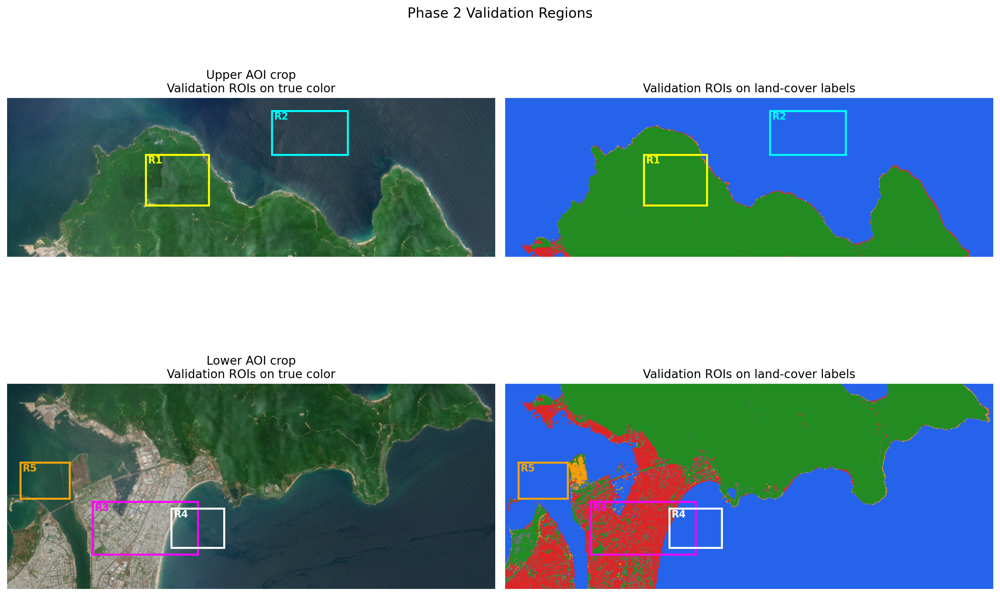

In [6]:
validation_regions = [
    {
        "id": "R1",
        "crop": "above",
        "roi": (220, 90, 100, 80),
        "expected_land_use": "Forested Son Tra hillside",
        "acceptable_labels": ["Dense vegetation"],
        "notes": "Should be mostly vegetation; small edge/water pixels can appear near steep coastal boundaries.",
    },
    {
        "id": "R2",
        "crop": "above",
        "roi": (420, 20, 120, 70),
        "expected_land_use": "Open coastal water",
        "acceptable_labels": ["Water"],
        "notes": "Dark offshore water is expected; this region tests whether water is separated from shadows.",
    },
    {
        "id": "R3",
        "crop": "below",
        "roi": (130, 180, 160, 80),
        "expected_land_use": "Dense urban/built-up grid",
        "acceptable_labels": ["Built-up/bare"],
        "notes": "Urban blocks include roads, rooftops, vegetation, and shadows, so mixed pixels are expected.",
    },
    {
        "id": "R4",
        "crop": "below",
        "roi": (250, 190, 80, 60),
        "expected_land_use": "Beach and nearshore water corridor",
        "acceptable_labels": ["Water", "Sand/exposed soil"],
        "notes": "A 10 m Sentinel-2 pixel can mix beach sand, surf, shallow water, and built edges.",
    },
    {
        "id": "R5",
        "crop": "below",
        "roi": (20, 120, 75, 55),
        "expected_land_use": "Harbor or bay water",
        "acceptable_labels": ["Water"],
        "notes": "Sediment and shallow water may reduce NDVI/NDWI separation near the shoreline.",
    },
]

validation_rows = []

fig, axes = plt.subplots(len(crops), 2, figsize=(14, 9), constrained_layout=True)
region_colors = ["yellow", "cyan", "magenta", "white", "orange"]
region_color_map = {region["id"]: region_colors[idx % len(region_colors)] for idx, region in enumerate(validation_regions)}

for row_idx, (crop_key, crop_label) in enumerate(crops.items()):
    rgb = scene_data[crop_key]["rgb"]
    label_image = segmentation_results[crop_key]["label_image"]
    labels = segmentation_results[crop_key]["labels"]
    georef = scene_data[crop_key]["georef"]

    axes[row_idx, 0].imshow(rgb)
    axes[row_idx, 0].set_title(f"{crop_label}\nValidation ROIs on true color")
    axes[row_idx, 1].imshow(label_image)
    axes[row_idx, 1].set_title("Validation ROIs on land-cover labels")

    for ax in axes[row_idx]:
        ax.axis("off")

    for region in [r for r in validation_regions if r["crop"] == crop_key]:
        x, y, w, h = region["roi"]
        roi_labels = labels[y:y+h, x:x+w]
        unique, counts = np.unique(roi_labels, return_counts=True)
        order = np.argsort(counts)[::-1]
        majority_id = int(unique[order[0]])
        majority_label = label_names[majority_id]
        majority_percent = float(counts[order[0]] / roi_labels.size * 100.0)
        accepted = majority_label in region["acceptable_labels"]
        status = "Match" if accepted else "Needs review"
        lon, lat = pixel_to_lonlat(georef, x + w / 2, y + h / 2)

        validation_rows.append({
            "region_id": region["id"],
            "crop": crop_key,
            "roi_x": x,
            "roi_y": y,
            "roi_w": w,
            "roi_h": h,
            "center_lon": lon,
            "center_lat": lat,
            "expected_land_use": region["expected_land_use"],
            "acceptable_labels": "; ".join(region["acceptable_labels"]),
            "majority_label": majority_label,
            "majority_percent": majority_percent,
            "status": status,
            "notes": region["notes"],
        })

        color = region_color_map[region["id"]]
        for ax in axes[row_idx]:
            rect = Rectangle((x, y), w, h, fill=False, edgecolor=color, linewidth=2.0)
            ax.add_patch(rect)
            ax.text(x + 3, y + 13, region["id"], color=color, fontsize=10, weight="bold")

validation_path = output_dir / "phase2_validation_regions.csv"
with validation_path.open("w", newline="") as f:
    writer = csv.DictWriter(
        f,
        fieldnames=[
            "region_id", "crop", "roi_x", "roi_y", "roi_w", "roi_h", "center_lon", "center_lat",
            "expected_land_use", "acceptable_labels", "majority_label", "majority_percent", "status", "notes",
        ],
    )
    writer.writeheader()
    writer.writerows(validation_rows)

fig.suptitle("Phase 2 Validation Regions", fontsize=14)
save_figure(fig, "phase2_validation_regions_2024.png")
plt.show()

print(f"Saved: {validation_path}")
print("\nValidation summary")
for row in validation_rows:
    print(
        f"- {row['region_id']} ({row['crop']}): expected {row['expected_land_use']}; "
        f"majority={row['majority_label']} ({row['majority_percent']:.1f}%) -> {row['status']}"
    )


Saved: ../output/phase2_osm_basemap_reference.png


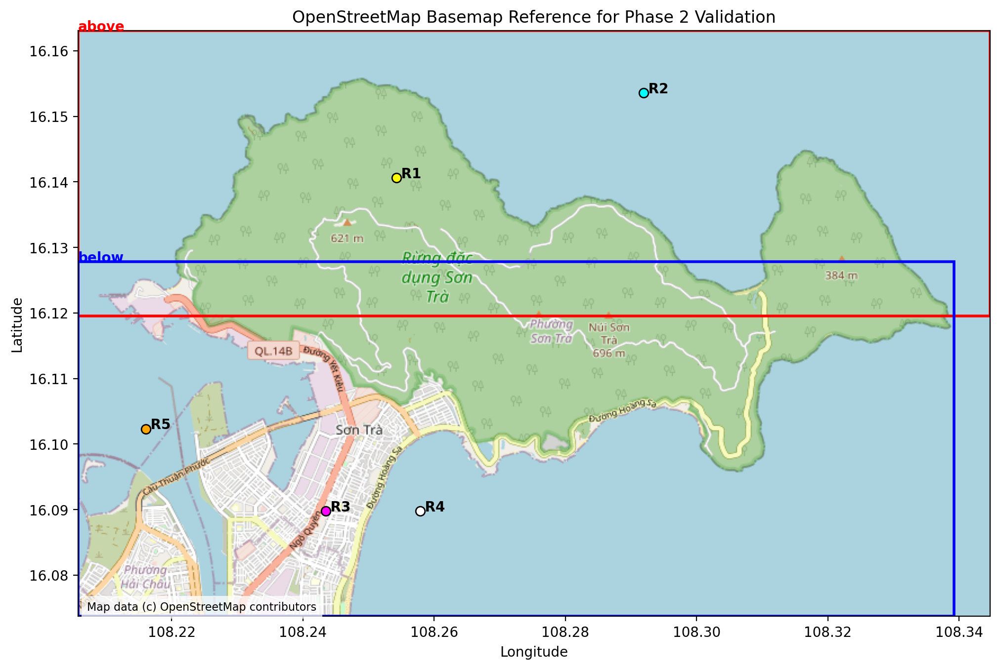

In [7]:
def lonlat_to_tile(lon, lat, zoom):
    lat = max(min(lat, 85.05112878), -85.05112878)
    lat_rad = math.radians(lat)
    n = 2 ** zoom
    x_tile = int((lon + 180.0) / 360.0 * n)
    y_tile = int((1.0 - math.asinh(math.tan(lat_rad)) / math.pi) / 2.0 * n)
    return x_tile, y_tile


def tile_bounds(x_tile, y_tile, zoom):
    n = 2 ** zoom
    lon_w = x_tile / n * 360.0 - 180.0
    lon_e = (x_tile + 1) / n * 360.0 - 180.0
    lat_n = math.degrees(math.atan(math.sinh(math.pi * (1 - 2 * y_tile / n))))
    lat_s = math.degrees(math.atan(math.sinh(math.pi * (1 - 2 * (y_tile + 1) / n))))
    return lon_w, lat_s, lon_e, lat_n


def fetch_osm_tile(x_tile, y_tile, zoom):
    url = f"https://tile.openstreetmap.org/{zoom}/{x_tile}/{y_tile}.png"
    request = urllib.request.Request(url, headers={"User-Agent": "CPV301-phase2-validation/1.0"})
    with urllib.request.urlopen(request, timeout=15) as response:
        return Image.open(response).convert("RGB")

lon_min = min(scene_data[crop]["georef"]["lon_min"] for crop in crops)
lon_max = max(scene_data[crop]["georef"]["lon_max"] for crop in crops)
lat_min = min(scene_data[crop]["georef"]["lat_min"] for crop in crops)
lat_max = max(scene_data[crop]["georef"]["lat_max"] for crop in crops)

zoom = 13
x_min, y_max = lonlat_to_tile(lon_min, lat_min, zoom)
x_max, y_min = lonlat_to_tile(lon_max, lat_max, zoom)

try:
    tile_size = 256
    mosaic = Image.new("RGB", ((x_max - x_min + 1) * tile_size, (y_max - y_min + 1) * tile_size))
    for x_tile in range(x_min, x_max + 1):
        for y_tile in range(y_min, y_max + 1):
            tile = fetch_osm_tile(x_tile, y_tile, zoom)
            mosaic.paste(tile, ((x_tile - x_min) * tile_size, (y_tile - y_min) * tile_size))

    tile_lon_w, tile_lat_s, _, _ = tile_bounds(x_min, y_max, zoom)
    _, _, tile_lon_e, tile_lat_n = tile_bounds(x_max, y_min, zoom)

    fig, ax = plt.subplots(figsize=(10, 8), constrained_layout=True)
    ax.imshow(mosaic, extent=[tile_lon_w, tile_lon_e, tile_lat_s, tile_lat_n])
    ax.set_xlim(lon_min, lon_max)
    ax.set_ylim(lat_min, lat_max)
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    ax.set_title("OpenStreetMap Basemap Reference for Phase 2 Validation")

    for crop_key, crop_label in crops.items():
        georef = scene_data[crop_key]["georef"]
        rect = Rectangle(
            (georef["lon_min"], georef["lat_min"]),
            georef["lon_max"] - georef["lon_min"],
            georef["lat_max"] - georef["lat_min"],
            fill=False,
            edgecolor="red" if crop_key == "above" else "blue",
            linewidth=2,
        )
        ax.add_patch(rect)
        ax.text(georef["lon_min"], georef["lat_max"], crop_key, color=rect.get_edgecolor(), weight="bold")

    for region in validation_rows:
        ax.scatter(region["center_lon"], region["center_lat"], s=45, color=region_color_map[region["region_id"]], edgecolor="black")
        ax.text(region["center_lon"], region["center_lat"], " " + region["region_id"], color="black", weight="bold")

    ax.text(
        0.01,
        0.01,
        "Map data (c) OpenStreetMap contributors",
        transform=ax.transAxes,
        fontsize=8,
        color="black",
        bbox={"facecolor": "white", "alpha": 0.75, "edgecolor": "none"},
    )
    save_figure(fig, "phase2_osm_basemap_reference.png")
    plt.show()
except Exception as exc:
    print(f"OSM basemap fetch skipped: {exc}")
    print("Validation CSV still contains ROI center lon/lat values for manual basemap checking.")


## Phase 2 Notes
Canny highlights coastlines, roads, riverbanks, and urban boundaries as edge structures. ORB keypoints concentrate around high-contrast corners and texture changes, especially urban grids, coastline curves, and forest-road boundaries.

Mean-shift filtering is used as the segmentation technique required by Phase 2. The filtered image groups nearby pixels with similar color before the notebook assigns interpretable land-cover classes using NDVI, NDWI, brightness, and saturation thresholds.

The validation regions are intentionally small and inspectable. They should be reviewed against Google Maps or an OpenStreetMap basemap for the same coordinates before the final written report. The notebook exports an OpenStreetMap reference image when internet access is available and writes ROI center coordinates to `phase2_validation_regions.csv`.
